# The two mechanisms acting on each other

Two phase diagrams sharing one $(\epsilon, \beta)$ frame, one for each direction of the interaction.

**Left — the Chameleon shrinks the Vainshtein sphere.** The ratio $x_{\rm V+Ch}/x_{\rm V}$ lies below unity everywhere. Two effects combine: the conformal coupling stiffens the kinetic term, contributing a fixed geometric ceiling $\tilde\alpha^{-2/3}$, and the screened core suppresses the charge the field actually sees. Where the sphere is pulled inside the source the mechanism is gone altogether.

**Right — the Vainshtein term de-screens the Chameleon core.** Inside a macroscopic Vainshtein sphere the nonlinear kinetic term caps the gradient, so the interior can no longer relax to its minimum. $\mathcal{D} = (y_0 - y_{\rm in})/(y_{\rm bg} - y_{\rm in})$ measures how far the centre is displaced: $0$ is a fully screened core, $1$ a lost one.

The comparison radius $x_{\rm V}$ is the **shift-symmetric** Galileon, with kinetic coefficient $\epsilon$ rather than $\epsilon\tilde\alpha$ — which is why the left panel saturates at $\tilde\alpha^{-2/3} \simeq 0.63$ rather than at 1.

In [1]:
import os, sys
sys.path.insert(0, os.path.abspath('.'))
sys.path.insert(0, os.path.abspath(os.path.join('..', '..', 'main')))

import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap
from matplotlib.patches import Patch

import styling
import phase_sweep as sweep

styling.apply()
plt.rcParams['hatch.linewidth'] = 0.35
_HG = 0.40
H_DIAG = (_HG, _HG, _HG, 1.0)        # Vainshtein: solid
H_DOTS = (_HG, _HG, _HG, 0.35)       # Chameleon: softened

from matplotlib.path import Path as _Path

def _hatch_colour(cs, col):
    """Colour a contourf's hatch. edgecolor drives the hatch but also strokes the
    region outline, so the linewidth is zeroed to keep only the hatch."""
    for o in ([cs] if hasattr(cs, 'set_edgecolor') else list(cs.collections)):
        o.set_edgecolor(col); o.set_linewidth(0)

def _dots(ax, cs, pitch_mm=1.9, ms=1.1):
    """Filled markers on a staggered lattice, clipped to a contourf region.
    matplotlib's '.' hatch strokes a circle outline, which reads as a ring
    rather than a dot, so real markers are used instead."""
    paths = cs.get_paths()
    if not paths:
        return
    ax.figure.canvas.draw()
    bb = ax.get_window_extent().transformed(ax.figure.dpi_scale_trans.inverted())
    pit = pitch_mm / 25.4
    nx = max(2, int(bb.width / pit)); ny = max(2, int(bb.height / pit))
    X, Y = np.meshgrid((np.arange(nx) + 0.5) / nx, (np.arange(ny) + 0.5) / ny)
    X[1::2] += 0.5 / nx                                  # stagger alternate rows
    sc = ax.scatter(X.ravel(), Y.ravel(), s=ms**2, color=H_DOTS, linewidths=0,
                    transform=ax.transAxes, zorder=3)
    sc.set_clip_path((_Path.make_compound_path(*paths), ax.transData))

## The sweeps

Both are cached. The reduction map is 100×100; the de-screening map is coarser in $\beta$, since each of its pixels is a deep-core solve.

In [2]:
def load(path, runner, label):
    """Load a cached sweep, recomputing if it is missing or was interrupted.

    The sweeps save after every eps column so a long run is not lost, which
    means a file can exist while still being partly unfilled. Trusting one of
    those silently is the easiest way to diff against placeholder NaNs.
    """
    if os.path.exists(path):
        d = np.load(path)
        if bool(d['complete']) if 'complete' in d.files else False:
            print(f'{label}: loaded cached sweep')
            return d
        print(f'{label}: cache is incomplete (interrupted run) -- recomputing')
    else:
        print(f'{label}: no cache -- computing')
    runner()
    return np.load(path)

red = load(sweep.OUT_RED, sweep.run_reduction, 'reduction')
dsc = load(sweep.OUT_DSC, sweep.run_descreening, 'de-screening')

ep, be = red['epss'], red['betas']
RAT, XV, LAM = red['RAT'], red['XV'], red['LAM']
cep, cbe, D = dsc['epss'], dsc['betas'], dsc['D']
AT = float(red['at']); RHO_IN = float(red['rho_in']); RHO_BG = float(red['rho_bg'])

ceiling = AT**(-2 / 3)
print(f'geometric ceiling at^(-2/3) = {ceiling:.4f};  max ratio found = {np.nanmax(RAT):.4f}')
print(f'reduction: {np.isfinite(RAT).sum()}/{RAT.size} solved, '
      f'{np.isnan(XV).sum()} with Vainshtein eliminated')
print(f'de-screening: {np.isfinite(D).sum()}/{D.size} solved, range '
      f'[{np.nanmin(D):.3f}, {np.nanmax(D):.3f}]')

reduction: loaded cached sweep
de-screening: loaded cached sweep
geometric ceiling at^(-2/3) = 0.6300;  max ratio found = 0.6313
reduction: 7971/10000 solved, 2029 with Vainshtein eliminated
de-screening: 10000/10000 solved, range [-0.000, 0.977]


## Analytic boundaries

Vainshtein screening is eliminated when the sphere no longer reaches outside the source, $x_{\rm V+Ch} < 1$. Setting $x_{\rm V+Ch} = 1$ gives a two-branch boundary: at low $\epsilon$ the charge is limited by the field excursion, at high $\epsilon$ by the total mass available.

The Chameleon boundary is read off the solved map at $\mathcal{D} = 0.1$.

In [3]:
y_bg = RHO_BG**-0.5
dy = y_bg - RHO_IN**-0.5          # field excursion from core to background
IV = RHO_IN / 3.0                 # total enclosed mass

epg = np.geomspace(ep[0], ep[-1], 400)
beg = np.geomspace(be[0], be[-1], 400)
EG, BG = np.meshgrid(epg, beg)
# contouring this at AT recovers the two-branch elimination boundary
GC = np.minimum(8 * dy * BG / (1.13 * EG), np.sqrt(8 * IV * BG) / EG)

# Chameleon boundary: where the solved D crosses 0.1, per beta row
bD = np.full(len(cbe), np.nan)
for i in range(len(cbe)):
    r = D[i, :]
    if np.isfinite(r).all() and r[0] < 0.1 < r[-1]:
        bD[i] = np.interp(0.1, r, cep)
mB = np.isfinite(bD); bDx, bDy = bD[mB], cbe[mB]
# at high beta the crossing leaves the left edge, so extend the curve to it
col0 = D[:, 0]
if np.any(col0 < 0.1) and np.any(col0 > 0.1):
    bDx = np.append(bDx, cep[0])
    bDy = np.append(bDy, np.interp(0.1, col0, cbe))
print(f'Chameleon D=0.1 boundary traced over {mB.sum()} of {len(cbe)} beta values')

Chameleon D=0.1 boundary traced over 68 of 100 beta values


## Figure

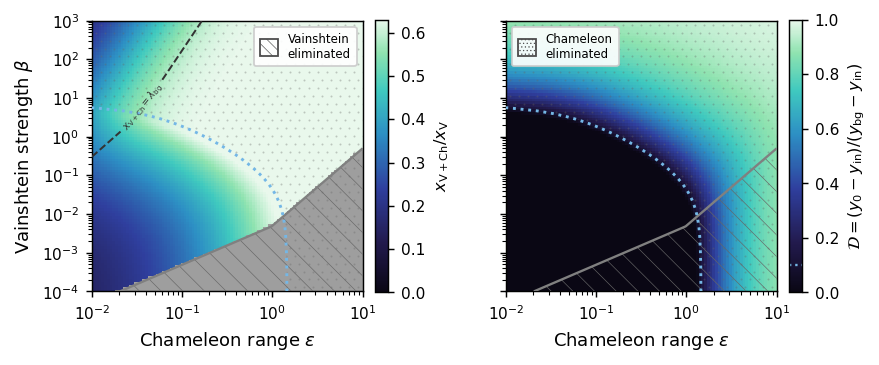

In [4]:
cmap = styling.sequential()
C_XS = '#74b7e6'          # Chameleon-elimination boundary
gray = ListedColormap(['0.62'])
CEP, CBE = np.meshgrid(cep, cbe)

def mark_regions(ax):
    """Hatch where each mechanism is gone, and draw both boundaries."""
    cs1 = ax.contourf(EG, BG, GC, levels=[GC.min(), AT], colors='none',
                      hatches=['\\\\'], zorder=3)
    _hatch_colour(cs1, H_DIAG)
    cs2 = ax.contourf(CEP, CBE, D, levels=[0.1, np.nanmax(D) + 0.01],
                      colors='none', zorder=3)
    _dots(ax, cs2)
    ax.contour(EG, BG, GC, levels=[AT], colors='0.5', linewidths=1.3, zorder=4)
    ax.plot(bDx, bDy, color=C_XS, lw=1.6, ls=':', zorder=4)

fig = plt.figure(figsize=(styling.WIDE, 3.4))
gs = fig.add_gridspec(1, 3, width_ratios=[1, 0.32, 1], wspace=0.05)
axa, axb = fig.add_subplot(gs[0]), fig.add_subplot(gs[2])

# ---- (a) Vainshtein-radius reduction ----
# XV is NaN both where the mechanism is eliminated and (in principle) where a
# solve failed. Only the former is a physical result, so the grey region is
# taken from the convergence mask rather than from NaN alone.
solved = red['SOLVED'] if 'SOLVED' in red.files else np.isfinite(LAM)
eliminated = solved & ~np.isfinite(XV)
unsolved = ~solved
if unsolved.any():
    print(f'WARNING: {unsolved.sum()} pixel(s) did not converge; '
          'these are left blank, not drawn as eliminated')
ima = axa.pcolormesh(ep, be, np.ma.masked_where(~np.isfinite(XV), RAT),
                     cmap=cmap, shading='nearest', vmin=0, vmax=ceiling)
axa.pcolormesh(ep, be, np.ma.masked_where(~eliminated, np.ones_like(RAT)),
               cmap=gray, shading='nearest')
mark_regions(axa)
EP, BE = np.meshgrid(ep, be)
csC = axa.contour(EP, BE, np.where(np.isfinite(XV), XV - LAM, np.nan), levels=[0],
                  colors='0.2', linewidths=1.1, linestyles='dashed', zorder=4)

# ---- (b) Chameleon core de-screening ----
imb = axb.pcolormesh(cep, cbe, D, cmap=cmap, shading='nearest', vmin=0, vmax=1)
mark_regions(axb)

for ax in (axa, axb):
    ax.set_xscale('log'); ax.set_yscale('log')
    ax.set_xlim(ep[0], ep[-1]); ax.set_ylim(be[0], be[-1])
    ax.set_xlabel(r'Chameleon range $\epsilon$'); ax.set_box_aspect(1)
axa.set_ylabel(r'Vainshtein strength $\beta$'); axb.set_yticklabels([])

fig.colorbar(ima, ax=axa, fraction=0.046, pad=0.04).set_label(
    r'$x_{\rm V+Ch}/x_{\rm V}$', fontsize=9)
cbb = fig.colorbar(imb, ax=axb, fraction=0.046, pad=0.04)
cbb.set_label(r'$\mathcal{D}=(y_0-y_{\rm in})/(y_{\rm bg}-y_{\rm in})$', fontsize=9)
cbb.ax.axhline(0.1, color=C_XS, lw=1.3, ls=':')
fig.canvas.draw()

axa.clabel(csC, fmt={0.0: r'$x_{\rm V+Ch}=\lambda_{\rm bg}$'}, fontsize=5.5,
           manual=[(0.03, 8)], colors='0.2')
axa.legend(handles=[Patch(facecolor='none', edgecolor='0.3', hatch='\\\\\\\\',
                          label='Vainshtein\neliminated')],
           loc='upper right', fontsize=6.5, framealpha=0.92,
           handlelength=1.6, handleheight=1.8, borderpad=0.5)
axb.legend(handles=[Patch(facecolor='none', edgecolor='0.3', hatch='......',
                          label='Chameleon\neliminated')],
           loc='upper left', fontsize=6.5, framealpha=0.92,
           handlelength=1.6, handleheight=1.8, borderpad=0.5)

fig.savefig('phase_diagrams.png', bbox_inches='tight', dpi=200)
plt.show()